# TOPIC 794 — LAB 04 | The Central Bank's Institutional Memory
## A Second Brain for precedent-aware, evidence-governed policy judgment

**Audience:** central bankers, financial supervisors, economists, investment bankers, and advanced graduate students.  
**Architecture:** Markdown vault → typed evidence graph → temporal and causal paths → relevance ranking → evidence package → Claude Haiku 5.5 → policy memo → audit.  
**Working root:** `/content/drive/MyDrive/Colab Notebooks/TOPIC_794 SECOND BRAIN CENTRAL BANK`  
**Mode:** complete synthetic experiment; no actual central-bank confidential information or real-world policy recommendation.

### Introduction — What it would mean for a central bank to remember

A central bank accumulates an extraordinary amount of knowledge without necessarily becoming an institution that remembers in a computationally usable sense. Its institutional memory resides in minutes, staff papers, financial-market reports, communications, operational records, monetary policy decisions, financial stability assessments, crisis exercises, and the private recollections of professionals who gradually retire or rotate into new positions. Some of these artifacts describe facts, others describe hypotheses; still others document interventions whose rationale may no longer be visible in the final public announcement. The institutional problem is therefore not merely that information is abundant. It is that the relationship between circumstances, evidence, judgment, action, and outcomes is usually dispersed across documents, times, and organizational units.

The modern language-model interface appears to offer an immediate solution: place documents into a retrieval system, ask a question, and let the model summarize the most relevant paragraphs. But for serious policy analysis this approach is incomplete. A document concerning liquidity stress may look very similar to a contemporary liquidity episode, while describing a banking structure, monetary regime, collateral framework, and set of legal powers that differ fundamentally from those of today. Conversely, an older episode with different vocabulary may contain a relevant causal mechanism. Similarity between texts is not the same as similarity between institutional problems. A central bank should not learn the wrong lesson merely because two documents share the same keywords.

Our laboratory develops a different paradigm. We construct a synthetic central-bank vault whose constituent notes preserve decisions, crisis episodes, market indicators, policy instruments, legal authority, research, causal mechanisms, operational constraints, and ex-post outcomes. A decision is not a document floating in a search index. It is a node connected to the symptoms that motivated it, the intervention selected, the mechanism hypothesized, the authority that enabled it, and the observations that followed. We also preserve an essential distinction between information available at the time of the decision and evidence assembled afterward. Without such temporal separation, apparent policy wisdom can be manufactured by hindsight.

The experimental challenge concerns a hypothetical liquidity disturbance: secured funding rates rise, collateral haircuts widen, a subset of otherwise solvent intermediaries has difficulty funding marketable assets, and the central bank must prepare a recommendation for its financial-stability committee. The decision is not predetermined. The committee could consider a targeted liquidity facility, enhanced collateral arrangements, market monitoring, communication, or no intervention pending further evidence. Different precedents will favor different interpretations. The Second Brain is expected to surface supportive and contradictory evidence instead of manufacturing unanimity.

We distinguish four representations. The Markdown vault is the durable, inspectable source of institutional material. A typed knowledge graph expresses relationships between notes. A temporal view tests whether sources and episodes are eligible as contemporaneous evidence or only ex-post evaluation. A causal view traces hypothesized links between shocks, instruments, market transmission, and outcomes. These representations are complementary: the human-friendly vault can be reviewed by policy analysts; the graph supports computational navigation; the time dimension prevents leakage of future facts; and causal chains require investigators to articulate how a past intervention was supposed to work.

This notebook will also differentiate deterministic retrieval from model-mediated judgment. Deterministic retrieval is inspectable and reproducible, but it is limited by the graph schema, the seed-selection rules, and the ranking function designed by the instructor. Claude Haiku 5.5 is not asked to invent vault facts, and it is not permitted to rewrite the evidence graph. Its job is to interpret a compact evidence packet, assess historical analogy, identify material disanalogies, and draft a qualified policy memorandum with explicit citations to synthetic note IDs. A small optional adaptive-discovery exercise permits the model to request one additional valid node through a controlled interface, illustrating how agentic discovery may augment rather than replace a governed evidence backbone.

The distinction between evidence and recommendation is central. A graph edge marked *supported_by* is a claim of provenance; an edge marked *causes* is only a proposed causal relationship until evidence warrants the stronger interpretation. The educational case deliberately encodes correlations, contested channels, alternative explanations, and limited outcomes. The system will not claim that an observed improvement conclusively proves the efficacy of an intervention. The committee memorandum should therefore separate observations from causal inference, and recommendations from the authority to act.

Another design commitment concerns institutional governance. Source notes have IDs, dates, classes, sensitivity labels, and synthetic provenance. The graph builder validates references and avoids silently inventing missing nodes. The retriever enforces a query cutoff for ex-ante policy analysis, with an explicit exception for the properly labeled ex-post assessment of *historical* episodes. The output includes path explanations, rejected precedents, unresolved questions, and a verification report. These controls cannot eliminate the possibility of error, but they make error easier to discover, diagnose, and correct.

We evaluate the laboratory on more than whether a polished answer appears. We ask whether the required precedent chain is present, whether unauthorized notes are absent, whether supporting evidence can be traced back to Markdown files, whether contradictory observations survive retrieval, whether the model cites known IDs, and whether the resulting recommendation remains cautious in the face of uncertainty. The use of a synthetic dataset is intentional: it permits known-answer tests and makes pedagogy reproducible without implying access to any real central bank's privileged internal information.

The resulting laboratory is a miniature model of institutional intelligence. Its purpose is not to replace central bankers with an autonomous policy oracle. Rather, it asks how an institution can make its accumulated experience navigable, subject it to structured scrutiny, and make the boundary between memory and judgment explicit. This is the conceptual progression from storing information, through searching information, to reasoning responsibly about what past experience can and cannot teach us about a new decision.

### Learning objectives

1. Construct a persistent Obsidian-compatible institutional vault with transparent synthetic provenance.
2. Derive a typed, temporally aware knowledge graph and inspect its topology.
3. Traverse from a current problem to historical decisions, evidence, authorities, outcomes, and counterarguments.
4. Compare deterministic retrieval with a bounded LLM-guided discovery step.
5. Produce an auditable, uncertainty-aware policy memorandum without granting an LLM authority over policy.

**Run instructions:** Execute the code cells from top to bottom. Mount Drive when prompted. For live Claude, set `ANTHROPIC_API_KEY` in Colab Secrets; otherwise the deterministic demonstration and diagnostic outputs still run. The synthetic vault is recreated deterministically inside the specified root.

### Cell 01 | 01 — Environment, persistence, and control flags

The first cell creates the laboratory's working environment. A Second Brain is not just a temporary notebook variable; it is an institutional artifact that must survive individual execution sessions. We therefore separate the persistent vault, exported graphs, analytical outputs, and audit records into explicit directories. In Google Colab the preferred location is the requested Google Drive folder. When Drive mounting is unavailable—such as when the notebook is tested outside Colab—the code uses a local fallback so the mechanics remain inspectable. This fallback is announced rather than hidden, because persistence is itself part of the research design.

The notebook has two execution modes. The core synthetic investigation requires no external model. It creates notes, builds a graph, traces evidence paths, assembles an evidence packet, and generates a rule-based diagnostic report. The live mode additionally invokes Claude Haiku 5.5 through the Anthropic API, with the key obtained from Colab Secrets or an environment variable. Absence of credentials must not cause the entire notebook to fail. A model response is a judgment layer; it should not be a single point of failure for the underlying evidence infrastructure.

We set a fixed random seed, define a stable decision date, and encode the case as a structured problem statement. This makes clear the distinction between simulated current information and historical evidence. Code here deliberately avoids placing a password in the notebook or writing it to Drive. Dependencies are installed when needed. The current Claude model does not require a temperature setting; including unsupported sampling parameters would make an otherwise valid policy experiment fail before any judgment is produced. Finally, we initialize a machine-readable audit log: the trace of what the laboratory computed is almost as important as its final prose.

In [ ]:
import os, sys, json, re, hashlib, subprocess, importlib.util, random, textwrap
from pathlib import Path
from collections import Counter, defaultdict, deque
from datetime import date
random.seed(794)
for package, module in [('networkx','networkx'),('pandas','pandas'),('matplotlib','matplotlib'),('anthropic','anthropic')]:
    if importlib.util.find_spec(module) is None:
        try:
            subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', package, '--retries', '1', '--timeout', '5'])
        except subprocess.CalledProcessError:
            if package != 'anthropic': raise
            print('Optional Anthropic SDK not installed; deterministic lab remains available.')
import pandas as pd, networkx as nx, matplotlib.pyplot as plt
DRIVE_ROOT=Path('/content/drive/MyDrive/Colab Notebooks/TOPIC_794 SECOND BRAIN CENTRAL BANK')
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    ROOT=DRIVE_ROOT
except Exception as exc:
    ROOT=Path('/content/TOPIC_794 SECOND BRAIN CENTRAL BANK') if Path('/content').exists() else Path.cwd()/'TOPIC_794 SECOND BRAIN CENTRAL BANK'
    print('Drive unavailable; local execution fallback:', type(exc).__name__)
VAULT=ROOT/'vault'; GRAPHS=ROOT/'graphs'; OUTPUT=ROOT/'outputs'; AUDIT=ROOT/'audit'
for p in [VAULT, GRAPHS, OUTPUT, AUDIT]: p.mkdir(parents=True, exist_ok=True)
MODEL='claude-haiku-5-5'
LIVE_LLM=True  # Set False to prohibit API calls
CUTOFF='2026-10-14'
QUERY={'id':'CURRENT_2026','date':CUTOFF,'title':'Collateralized market funding disruption',
       'question':'Should a synthetic central bank consider a targeted collateralized liquidity facility, under what guardrails, and what alternatives merit consideration?',
       'symptoms':['repo rate spike','collateral haircut widening','solvent dealers funding stress','market dysfunction'],
       'mechanisms':['secured funding squeeze','collateral spiral','market liquidity fragmentation'],
       'objectives':['market functioning','limit moral hazard','respect mandate']}
AUDIT_LOG=[]
def log(event, **payload): AUDIT_LOG.append({'event':event,'at_cell':payload.pop('at_cell',None),**payload})
def save_json(path, value): Path(path).write_text(json.dumps(value,indent=2,ensure_ascii=False,default=str),encoding='utf-8')
save_json(OUTPUT/'query.json',QUERY)
print('ROOT:',ROOT,'| MODEL:',MODEL,'| live requested:',LIVE_LLM)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ROOT: /content/drive/MyDrive/Colab Notebooks/TOPIC_794 SECOND BRAIN CENTRAL BANK | MODEL: claude-haiku-5-5 | live requested: True


### Cell 02 | 02 — Generate the synthetic institutional Markdown vault

Our second cell constructs the raw material from which institutional memory will be derived. We deliberately choose Markdown because it can be read and edited by humans, stored under version control, and opened in tools such as Obsidian. Each note has a YAML-like metadata header, a narrative body, and an explicit list of typed relationships. This is an important pedagogical point: the knowledge graph should not be a mysterious new source of truth. It must be reconstructable from the same evidence that analysts can inspect.

The synthetic institution has experienced several historical episodes: a repo-market dislocation, a currency-funding episode, and a payments-operational interruption. The latter is especially useful as a counterexample. All three episodes contain language related to liquidity; only some share the causal mechanism of the hypothetical present disturbance. We add central-bank actions, eligible collateral, legal mandates, supervisory coordination, research notes, indicators, and ex-post evaluations. Not every past intervention is successful or transferable. Several notes deliberately encode competing interpretations of outcome data and residual moral-hazard concerns.

The vault includes explicit event dates and knowledge-availability dates. A research note written after a crisis may be valuable for interpreting that historical crisis, but it could not have informed the original decision. This matters whenever we compare the information available to a historical committee with what we know after observing the outcome. The note classes also distinguish a measurement from a policy hypothesis, and an authorization from a recommendation. Those differences are not cosmetic: downstream scoring, context construction, and auditability depend on preserving their meanings. By generating the same synthetic notes on every run, we secure a fixed educational benchmark. More realistic vault ingestion would preserve original files and use a separate indexing pipeline.

**Repair and reproducibility note.** The cell now writes real `[[target-note-ID]]` wikilinks in the Markdown body, alongside machine-readable typed links in the frontmatter. Both originate from the same `EDGES` list. Opening the generated `vault/` directory in Obsidian will show connected notes rather than isolated nodes.

**Expanded corpus:** This cell produces exactly **260 synthetic Markdown notes**: the original 26 anchor records plus 18 additional, explicitly hypothetical episodes with 13 notes each. Every directed relationship is materialized as an outgoing `[[wikilink]]` in the vault, and incoming relationships are shown for navigation. Note types include episodes, decisions, mechanisms, instruments, authorities, constraints, indicators, outcomes, research, communications and assessments. Neither events nor measurements should be mistaken for real central-bank records.


In [ ]:
# 18 explicitly SYNTHETIC episodes, each with 13 interconnected records.
# Preserve the original 26 central-bank educational notes as anchors.
BASE_NOTES = [('E_REPO', 'episode', '2019-09-20', '2019-10-01', 'Repo-market funding dislocation', 'Repo rates spiked; dealers reduced intermediation. Collateral availability and settlement frictions amplified secured funding pressure.', 'repo rate spike; secured funding squeeze; collateral spiral; market dysfunction', 4), ('E_FX', 'episode', '2020-03-18', '2020-04-02', 'Cross-border foreign-currency funding squeeze', 'Global demand for dollar funding intensified. Currency swap arrangements helped banks access offshore funding but differed from domestic repo interventions.', 'market liquidity fragmentation; dollar shortage; foreign exchange', 3), ('E_PAY', 'episode', '2022-06-14', '2022-06-16', 'Payments infrastructure outage', 'A settlement software incident created temporary payment delays. The dominant cause was operational rather than a collateral-funding spiral.', 'liquidity stress; settlement outage; operations', 2), ('D_REPO', 'decision', '2019-09-22', '2019-09-22', 'Temporary secured market liquidity operations', 'Committee approved temporary collateralized operations; eligibility standards and sunset review applied.', 'repo; temporary operations; market functioning', 4), ('D_FX', 'decision', '2020-03-20', '2020-03-20', 'Foreign currency liquidity coordination', 'Committee authorized coordination subject to foreign-currency authority, tenor limits, and reporting.', 'currency swap; funding', 4), ('D_PAY', 'decision', '2022-06-14', '2022-06-14', 'Operational settlement contingency', 'Operational team prioritized restoration and settlement continuity without interpreting the event as market collateral scarcity.', 'settlement; operational continuity', 4), ('M_REPO', 'mechanism', '2019-09-20', '2019-09-25', 'Collateral funding feedback loop', 'Higher repo rates and haircuts force deleveraging, asset liquidation, and additional haircuts; intervention may interrupt the loop.', 'collateral spiral; secured funding squeeze', 4), ('M_FX', 'mechanism', '2020-03-18', '2020-03-25', 'Currency funding basis channel', 'Foreign-currency basis deviations and offshore funding frictions transmit stress across currency markets.', 'market liquidity fragmentation; foreign exchange', 3), ('M_PAY', 'mechanism', '2022-06-14', '2022-06-16', 'Settlement operations bottleneck', 'Queue management and software restoration are the key channels; broad liquidity operations may not fix the cause.', 'settlement outage; operations', 4), ('P_FAC', 'instrument', '2019-09-22', '2019-09-22', 'Targeted collateralized liquidity facility', 'Time-limited collateralized support subject to eligible assets, haircuts, counterparty standards, and monitoring.', 'repo; collateral; eligible counterparties', 4), ('P_SWAP', 'instrument', '2020-03-20', '2020-03-20', 'FX swap backstop', 'Foreign currency funding intervention, contingent on swap agreement, legal authority, and counterparties.', 'foreign exchange; currency swap', 3), ('P_OPER', 'instrument', '2022-06-14', '2022-06-14', 'Settlement contingency protocol', 'Restore payments service, communicate outages, and monitor intraday credit.', 'settlement; operational continuity', 4), ('A_LAW', 'authority', '2018-01-01', '2018-01-01', 'Central bank liquidity authority', 'Synthetic mandate permits temporary secured liquidity operations conditional on financial stability necessity and Board approval. This is not a statement of any real law.', 'mandate; Board approval; secured operations', 5), ('A_RISK', 'constraint', '2018-01-01', '2018-01-01', 'Collateral eligibility and risk governance', 'Conservative haircuts, solvency assessment, risk committee approval, disclosure protocol, and sunset restrictions are required.', 'collateral; moral hazard; governance', 5), ('A_FX', 'authority', '2018-01-01', '2018-01-01', 'Cross-currency funding authority', 'Swap-line deployment requires a separate authorization and availability of external counterparties.', 'currency swap; foreign exchange', 4), ('I_RATE', 'indicator', '2019-09-20', '2019-09-20', 'Repo premium series', 'Observed secured overnight funding premium rises during the repo episode. Synthetic measurement for the exercise.', 'repo rate spike; secured funding squeeze', 5), ('I_HAIR', 'indicator', '2019-09-20', '2019-09-20', 'Collateral haircut series', 'Observed financing haircuts widened during the repo episode. Synthetic measurement for the exercise.', 'collateral haircut widening; collateral spiral', 5), ('O_REPO', 'outcome', '2019-10-15', '2019-10-16', 'Repo functioning partially restored', 'Funding premiums declined after operations; causality is not identified because fiscal settlement patterns also shifted.', 'repo rates normalized; market functioning', 4), ('O_FX', 'outcome', '2020-05-01', '2020-05-06', 'FX basis narrowed', 'Cross-currency basis narrowed during a period of several simultaneous policy measures; attribution remains uncertain.', 'basis normalization; policy mix', 4), ('O_PAY', 'outcome', '2022-06-15', '2022-06-16', 'Payments restored', 'Queues cleared after systems repair and contingency operations; no evidence of collateral-induced market spiral.', 'settlement; operations', 4), ('R_ALT', 'research', '2021-02-04', '2021-02-04', 'Alternative explanation for repo normalization', 'Calendar effects, dealer balance-sheet changes, and private funding supply may explain part of normalization independently of liquidity operations.', 'counterargument; causal uncertainty; repo', 5), ('R_HAZ', 'research', '2021-05-10', '2021-05-10', 'Moral hazard and liquidity facility design', 'Persistent backstops may encourage liquidity risk-taking unless pricing, eligibility, and exit are enforced.', 'moral hazard; governance', 5), ('R_COMPARE', 'research', '2023-09-09', '2023-09-09', 'Comparative precedent assessment', 'Compare market structure, currency regime, collateral framework, and operational roots before transferring a policy intervention.', 'analogy; precedent; collateral', 5), ('C_CURRENT', 'current', '2026-10-14', '2026-10-14', 'Current hypothetical committee scenario', 'Repo rate spike, collateral haircut widening, solvent dealer funding stress, and impaired market functioning; synthetic and not validated.', 'repo rate spike; collateral haircut widening; secured funding squeeze', 5), ('S_SOLV', 'constraint', '2026-10-14', '2026-10-14', 'Current solvency verification requirement', 'Before intervention the central bank must establish which firms are solvent, identify liquidity versus solvency risk, and set eligibility triggers.', 'solvent dealers funding stress; moral hazard', 5), ('S_BASE', 'research', '2026-10-14', '2026-10-14', 'Current counterfactual question', 'Determine whether market funding normalizes without intervention and how timing of issuance, settlement, and nonpolicy actions influence spreads.', 'counterfactual; repo; no intervention', 5)]
BASE_EDGES = [('C_CURRENT', 'M_REPO', 'suggests'), ('C_CURRENT', 'I_RATE', 'resembles'), ('C_CURRENT', 'I_HAIR', 'resembles'), ('C_CURRENT', 'S_SOLV', 'requires'), ('C_CURRENT', 'S_BASE', 'requires'), ('E_REPO', 'M_REPO', 'exhibits'), ('E_REPO', 'I_RATE', 'observed'), ('E_REPO', 'I_HAIR', 'observed'), ('E_REPO', 'D_REPO', 'prompted'), ('D_REPO', 'P_FAC', 'decided_to_use'), ('D_REPO', 'A_LAW', 'requires_authority'), ('P_FAC', 'A_RISK', 'constrained_by'), ('P_FAC', 'O_REPO', 'followed_by'), ('R_ALT', 'O_REPO', 'challenges_attribution'), ('R_HAZ', 'P_FAC', 'challenges_design'), ('E_FX', 'M_FX', 'exhibits'), ('E_FX', 'D_FX', 'prompted'), ('D_FX', 'P_SWAP', 'decided_to_use'), ('P_SWAP', 'A_FX', 'requires_authority'), ('P_SWAP', 'O_FX', 'followed_by'), ('E_PAY', 'M_PAY', 'exhibits'), ('E_PAY', 'D_PAY', 'prompted'), ('D_PAY', 'P_OPER', 'decided_to_use'), ('P_OPER', 'O_PAY', 'followed_by'), ('R_COMPARE', 'E_REPO', 'assesses'), ('R_COMPARE', 'E_FX', 'assesses'), ('R_COMPARE', 'E_PAY', 'assesses'), ('S_SOLV', 'A_RISK', 'requires'), ('M_REPO', 'P_FAC', 'potentially_mitigated_by')]
SCENARIOS = [('SOV', 'Sovereign collateral volatility', '2017-04-10', 'sovereign bond repricing', 'margin spiral', 'targeted term repos', 'sovereign collateral concentration'), ('MMF', 'Money-market fund redemptions', '2018-06-05', 'fund redemption pressure', 'fire-sale feedback', 'temporary dealer liquidity', 'nonbank counterparty eligibility'), ('REPX', 'Cross-market repo stress', '2019-10-03', 'repo funding squeeze', 'dealer intermediation limits', 'repo auction calibration', 'dealer concentration'), ('DOLL', 'Offshore dollar funding episode', '2020-03-19', 'dollar shortage', 'currency basis stress', 'coordinated currency funding', 'swap counterparty risk'), ('CORP', 'Corporate credit market dislocation', '2020-04-08', 'credit spread widening', 'primary issuance blockage', 'collateral eligibility extension', 'credit allocation'), ('PAY2', 'High-value payment queue disruption', '2021-02-16', 'payment queue congestion', 'settlement gridlock', 'intraday liquidity bridge', 'operational cyber resilience'), ('CYB', 'Cyber incident at settlement utility', '2021-09-23', 'payment systems disruption', 'operational contagion', 'contingency payment rail', 'system integrity verification'), ('GILT', 'Pension-fund margin stress', '2022-09-28', 'margin call spiral', 'forced gilt sales', 'time-limited gilt backstop', 'exit strategy credibility'), ('COM', 'Commodity clearing liquidity stress', '2022-11-09', 'central counterparty margin pressure', 'commodity hedge liquidation', 'margin liquidity operations', 'CCP default waterfall'), ('REG', 'Regional-bank deposit flight', '2023-03-13', 'rapid insured uninsured deposit flows', 'deposit contagion', 'term liquidity window', 'solvency liquidity separation'), ('DIG', 'Digital bank-run dynamics', '2023-05-04', 'digital deposit acceleration', 'social media contagion', 'collateralized emergency line', 'moral hazard'), ('CBDC', 'Retail payment migration shock', '2023-10-12', 'settlement volume migration', 'bank reserves redistribution', 'reserve reallocation facility', 'payment privacy constraints'), ('FXG', 'Emerging-market FX basis dislocation', '2024-02-07', 'FX liquidity fragmentation', 'cross currency basis widening', 'FX repo swap arrangement', 'jurisdictional authority'), ('CCP', 'Clearinghouse concentration episode', '2024-05-17', 'CCP margin concentration', 'clearing member deleveraging', 'eligible collateral transformation', 'loss mutualization'), ('CLIM', 'Climate shock to collateral values', '2024-09-03', 'regional collateral devaluation', 'insurance repricing feedback', 'temporary collateral margin review', 'climate risk pricing'), ('STBL', 'Stablecoin redemption stress', '2025-01-21', 'token redemption pressure', 'bank deposit transmission', 'supervisory liquidity coordination', 'legal perimeter uncertainty'), ('AIQ', 'Algorithmic liquidity withdrawal', '2025-06-12', 'automated quote withdrawal', 'correlated market making', 'market functioning consultation', 'model governance'), ('XSET', 'Cross-border settlement interruption', '2025-11-18', 'cross-border settlement delays', 'correspondent network fragility', 'bilateral liquidity coordination', 'jurisdictional coordination')]
NOTES=list(BASE_NOTES); EDGES=list(BASE_EDGES)
from datetime import datetime,timedelta
for i,(slug,label,start_date,shock,mechanism,instrument,risk) in enumerate(SCENARIOS,1):
    start=datetime.strptime(start_date,'%Y-%m-%d')
    def dt(days): return (start+timedelta(days=days)).strftime('%Y-%m-%d')
    # id, kind, event date, first known date, title, content, tags, reliability score
    records=[
      ('E','episode',0,2,f'{label}: hypothetical crisis episode',f'Synthetic episode exhibiting {shock}. The committee must distinguish funding distress from insolvency, establish a baseline, and understand {mechanism}.',f'{shock}; {mechanism}; market functioning',4),
      ('D','decision',3,3,f'{label}: committee policy deliberation',f'Illustrative committee considered {instrument} and alternative non-intervention with detailed verification and sunset requirements.',f'committee; intervention; {instrument}',4),
      ('M','mechanism',0,4,f'{label}: causal transmission mechanism',f'Working hypothesis: {shock} propagates through {mechanism}. Alternative market-driven explanations remain plausible and are separately recorded.',f'{shock}; {mechanism}; counterfactual',4),
      ('P','instrument',3,3,f'{label}: candidate liquidity instrument',f'Proposed response is {instrument}, conditional on collateral eligibility, counterparties, pricing, reporting, and a defined termination date.',f'{instrument}; liquidity; prudential guardrails',4),
      ('A','authority',-100, -100,f'{label}: delegated instrument authority',f'Synthetic authority statement. Board approval and legal review are required before deploying {instrument}; this is not real central-bank law.',f'authority; legal; {instrument}',5),
      ('C','constraint',1,1,f'{label}: relevant control and risk limits',f'Approval must address {risk}, firm solvency, collateral quality, exposure caps, equal treatment, disclosure, and independent monitoring.',f'{risk}; governance; solvency',5),
      ('I1','indicator',0,1,f'{label}: market price indicator',f'Synthetic indicator monitoring changes in spreads and funding costs associated with {shock}. Not observed real market data.',f'{shock}; price; synthetic series',4),
      ('I2','indicator',0,1,f'{label}: market quantity indicator',f'Synthetic indicator measuring liquidity, volume, queue depth or haircuts as appropriate to {mechanism}.',f'{mechanism}; market depth; synthetic series',4),
      ('O','outcome',25,27,f'{label}: observed result and limits of inference',f'Synthetic outcome: functioning partially stabilizes. The temporal association with {instrument} is not a causal identification; other factors may explain the change.',f'outcome; attribution; {instrument}',4),
      ('R1','research',45,47,f'{label}: ex-post causal review',f'Synthetic research considers calendar effects, private liquidity supply and confounding policy actions when evaluating whether {instrument} affected outcomes.',f'counterfactual; causal inference; {instrument}',5),
      ('R2','research',50,52,f'{label}: dissent and alternative explanation',f'Synthetic skeptical assessment questions the intervention, highlighting {risk} and the cost of maintaining a standing liquidity backstop.',f'counterargument; {risk}; governance',5),
      ('COMM','communication',4,4,f'{label}: official communication protocol',f'Synthetic public communication would explain eligibility, duration, objectives, uncertainty, and why the proposed intervention is not unconditional support.',f'communication; transparency; {instrument}',4),
      ('ASMT','assessment',55,57,f'{label}: lessons learned and transferability',f'Synthetic ex-post review assesses whether the {label.lower()} experience transfers to another episode given different institutional powers, market structure and causal channels.',f'precedent; lessons; {mechanism}',5)]
    keys={key:f'{slug}_{key}' for key,*_ in records}
    for key,kind,ev,kd,title,body,tags,trust in records:
        NOTES.append((keys[key],kind,dt(ev),dt(kd),title,body,tags,trust))
    links=[('E','M','exhibits'),('E','I1','observed'),('E','I2','observed'),('E','D','prompted'),
           ('D','P','decided_to_use'),('D','A','requires_authority'),('P','C','constrained_by'),
           ('P','O','followed_by'),('R1','O','challenges_attribution'),('R2','P','challenges_design'),
           ('ASMT','E','assesses'),('ASMT','R1','uses_evidence'),('ASMT','R2','uses_evidence'),
           ('COMM','D','communicates'),('C','A','governed_by'),('M','P','potentially_mitigated_by'),
           ('I1','M','signals'),('I2','M','signals'),('O','ASMT','informs')]
    EDGES.extend((keys[a],keys[b],r) for a,b,r in links)
    # Strong cross-episode institutional memory links are explicit typed edges.
    EDGES.extend([(keys['ASMT'],'R_COMPARE','uses_evidence'),
                  (keys['C'],'A_RISK','governed_by'),
                  (keys['D'],'A_LAW','requires_authority')])
    if slug in ('REPX','GILT','MMF','REG','DIG','AIQ','SOV','CCP','CLIM'):
        EDGES.extend([('C_CURRENT',keys['M'],'suggests'),(keys['ASMT'],'E_REPO','assesses')])
    elif slug in ('DOLL','FXG','XSET'):
        EDGES.append((keys['ASMT'],'E_FX','assesses'))
    elif slug in ('PAY2','CYB','CBDC'):
        EDGES.append((keys['ASMT'],'E_PAY','assesses'))

# Couple research across episodes within and between clusters to make browsing meaningful.
for a,b in zip(SCENARIOS,SCENARIOS[1:]):
    EDGES.append((a[0]+'_ASMT',b[0]+'_ASMT','compares_with'))
for a,b in [('SOV','GILT'),('MMF','REG'),('REPX','GILT'),('DOLL','FXG'),('CYB','PAY2'),('DIG','STBL'),('CCP','COM'),('AIQ','REPX'),('CLIM','SOV')]:
    EDGES.append((a+'_M',b+'_M','compares_with'))

assert len(NOTES)==260, len(NOTES)
assert len({n[0] for n in NOTES})==len(NOTES)
assert len(EDGES)==len({(u,v) for u,v,r in EDGES}), 'Duplicate directed edge would collapse in nx.DiGraph'
ALLOWED_RELATIONS={r for _,_,r in EDGES}
# Prevent stale notes from a previous run polluting the new vault.
for prior in VAULT.glob('*.md'): prior.unlink()
lookup={n[0]:n for n in NOTES}
for nid,kind,event,known,title,body,tags,trust in NOTES:
    outgoing=[{'target':v,'relation':r} for u,v,r in EDGES if u==nid]
    incoming=[{'source':u,'relation':r} for u,v,r in EDGES if v==nid]
    header={'id':nid,'kind':kind,'event_date':event,'known_date':known,
            'title':title,'trust':trust,'classification':'synthetic_public',
            'tags':[t.strip() for t in tags.split(';')],'links':outgoing}
    out_text='\n'.join(f'- **{e["relation"].replace("_"," ")}** → [[{e["target"]}]]' for e in outgoing)
    in_text='\n'.join(f'- **{e["relation"].replace("_"," ")}** ← [[{e["source"]}]]' for e in incoming)
    note=('---\n'+json.dumps(header,ensure_ascii=False,indent=2)+'\n---\n\n# '+title+'\n\n'+body+'\n\n'
       +'## Outgoing relationships (clickable Obsidian links)\n\n'+(out_text or '_No outgoing links._')+'\n\n'
       +'## Incoming relationships (navigable context)\n\n'+(in_text or '_No incoming links._')+'\n\n'
       +'> SYNTHETIC educational material; not a real institutional record.\n')
    (VAULT/(nid+'.md')).write_text(note,encoding='utf-8')
# Each typed edge must appear as an outgoing wiki-link in the actual note.
visible=set()
for fp in VAULT.glob('*.md'):
    outgoing_section=fp.read_text(encoding='utf-8').split('## Outgoing relationships (clickable Obsidian links)',1)[1].split('## Incoming relationships',1)[0]
    visible.update((fp.stem,x) for x in re.findall(r'\[\[([A-Za-z0-9_]+)\]\]',outgoing_section))
expected={(u,v) for u,v,_ in EDGES}
assert visible==expected,(len(visible),len(expected),len(visible^expected))
print(f'VAULT PASS: {len(NOTES)} Markdown notes and {len(EDGES)} typed edges; every edge is an outgoing Obsidian wikilink')
log('obsidian_vault_written',notes=len(NOTES),typed_edges=len(EDGES),integrity=True)


VAULT PASS: 260 Markdown notes and 475 typed edges; every edge is an outgoing Obsidian wikilink


### Cell 03 | 03 — Parse, validate, and index vault records

The third cell turns the textual vault into a structured catalog. Parsing and validation often seem unglamorous beside the apparent sophistication of language models, but they form the foundation of an auditable institutional system. A model should not infer the existence of a policy authority merely because a plausible legal reference appears in its training data. It should be shown an identifiable note carrying that authority claim, with an origin, date, and link to other evidence. We therefore read the vault from disk rather than reuse only the in-memory data that produced it.

Our validation rules inspect required metadata fields, uniqueness of IDs, legal relationship labels, and whether edges point to existing records. Broken links would otherwise be silently discarded or accidentally converted into new objects. We also distinguish event date from recorded-at date; both can matter in post-event analysis. We retain the Markdown path as a provenance handle for every node, allowing a policy analyst to open the original note whenever the graph raises a surprising result. An index table makes it possible to see whether some categories dominate the vault, which could bias retrieval.

A robust institutional implementation would add document-version identifiers, access permissions, source trust levels, editor identity, and immutable audit snapshots. Here we provide a simpler demonstration but preserve the corresponding design spaces in metadata. We also produce a checksum of the sorted vault files. The checksum does not demonstrate that content is true, but it tells us whether the input corpus changed between runs. That is enough to establish reproducibility for the following graph traversal. The cell's result is an inspected catalog, not a policy answer. This separation is intentional: transformations of evidence should be visible before any LLM is invited to interpret it.

In [ ]:
catalog={}; broken=[]
for fp in sorted(VAULT.glob('*.md')):
    raw=fp.read_text(encoding='utf-8'); match=re.match(r'^---\n(.*?)\n---\n',raw,re.S)
    if not match: raise ValueError('Missing structured frontmatter: '+str(fp))
    obj=json.loads(match.group(1)); obj['body']=raw[match.end():]; obj['path']=str(fp)
    if obj['id'] in catalog: raise ValueError('Duplicate ID '+obj['id'])
    for key in ['kind','event_date','known_date','title','links','trust']:
        if key not in obj: raise ValueError(f'Missing {key} in {fp}')
    catalog[obj['id']]=obj
for nid,obj in catalog.items():
    for link in obj['links']:
        if link['target'] not in catalog or link['relation'] not in ALLOWED_RELATIONS:
            broken.append((nid,link))
if broken: raise ValueError(f'Invalid graph references: {broken}')
corpus_digest=hashlib.sha256(''.join((p.name+p.read_text(encoding='utf-8')) for p in sorted(VAULT.glob('*.md'))).encode()).hexdigest()
inventory=pd.DataFrame([{'id':o['id'],'kind':o['kind'],'event_date':o['event_date'],'known_date':o['known_date'],'trust':o['trust']} for o in catalog.values()])
print('Validated notes:',len(catalog),'| corpus SHA-256:',corpus_digest[:18],'...')
print(inventory.groupby('kind').size().to_string()); display(inventory.head(10))
log('vault_validated',count=len(catalog),sha256=corpus_digest)
# Validate that EVERY declared directed edge is readable as an Obsidian wikilink.
visible_outgoing=set()
for nid,obj in catalog.items():
    raw=(VAULT/(nid+'.md')).read_text(encoding='utf-8')
    outgoing_body=raw.split('## Outgoing relationships (clickable Obsidian links)',1)[1].split('## Incoming relationships',1)[0]
    visible_outgoing.update((nid,target) for target in re.findall(r'\[\[([A-Za-z0-9_]+)\]\]',outgoing_body))
metadata_pairs={(nid,edge['target']) for nid,obj in catalog.items() for edge in obj['links']}
assert visible_outgoing==metadata_pairs, f'Obsidian/metadata mismatch: {visible_outgoing ^ metadata_pairs}'
assert len(metadata_pairs)==len(EDGES) and len(catalog)==260
print(f'OBSIDIAN INTEGRITY PASS: {len(visible_outgoing)} directional links in the note bodies match metadata exactly.')


Validated notes: 260 | corpus SHA-256: 3832be79d31b8294d7 ...
kind
assessment       18
authority        20
communication    18
constraint       20
current           1
decision         21
episode          21
indicator        38
instrument       21
mechanism        21
outcome          21
research         40


,id,kind,event_date,known_date,trust
0,AIQ_A,authority,2025-03-04,2025-03-04,5
1,AIQ_ASMT,assessment,2025-08-06,2025-08-08,5
2,AIQ_C,constraint,2025-06-13,2025-06-13,5
3,AIQ_COMM,communication,2025-06-16,2025-06-16,4
4,AIQ_D,decision,2025-06-15,2025-06-15,4
5,AIQ_E,episode,2025-06-12,2025-06-14,4
6,AIQ_I1,indicator,2025-06-12,2025-06-13,4
7,AIQ_I2,indicator,2025-06-12,2025-06-13,4
8,AIQ_M,mechanism,2025-06-12,2025-06-16,4
9,AIQ_O,outcome,2025-07-07,2025-07-09,4


OBSIDIAN INTEGRITY PASS: 475 directional links in the note bodies match metadata exactly.


#### Narrative of Wikilinks: From Problem to Solution

To trace how our Second Brain moves from a current market disturbance to an authoritative, evidence-governed policy action, we navigate through a sequence of typed links within the `vault/` corpus:

1. **The Entry Point:**  
   The investigation begins at [[C_CURRENT]] (*Current hypothetical committee scenario*), which records the live market symptoms including a repo rate spike and collateral haircut widening. This note immediately **suggests** the causal mechanism of a [[M_REPO]] (*Collateral funding feedback loop*).

2. **Historical Analogy:**  
   The current scenario [[C_CURRENT]] **resembles** past indicators [[I_RATE]] and [[I_HAIR]], which were actively **observed** during the landmark historical episode [[E_REPO]] (*Repo-market funding dislocation*).

3. **The Precedent Decision:**  
   In that historical case, the severe funding stress [[E_REPO]] **prompted** the policy decision [[D_REPO]] (*Temporary secured market liquidity operations*), where the committee officially **decided to use** the targeted instrument [[P_FAC]] (*Targeted collateralized liquidity facility*).

4. **Legal Authorization and Constraints:**  
   Deploying that instrument was not unconditional. The decision [[D_REPO]] **requires authority** under the central bank's legal mandate [[A_LAW]]. Furthermore, the actual execution of the facility [[P_FAC]] was strictly **constrained by** the risk framework [[A_RISK]] (*Collateral eligibility and risk governance*).

5. **The Outcome and Challenges:**  
   While the historical facility [[P_FAC]] was **followed by** a positive outcome [[O_REPO]] (*Repo functioning partially restored*), our Second Brain retrieves critical balance. Research paper [[R_ALT]] actively **challenges attribution** of that recovery solely to the central bank's actions, while [[R_HAZ]] **challenges design** by highlighting the chronic moral hazard risks of maintaining standing backstops.

6. **The Current Resolution:**  
   Returning to the present, [[C_CURRENT]] **requires** strict compliance with [[S_SOLV]] (*Current solvency verification requirement*), ensuring that any new facility deployment is governed by the risk rules of [[A_RISK]] before an intervention is recommended to the policy committee.

### Cell 04 | 04 — Derive typed knowledge graphs and visualize their architecture

This cell constructs the computational graph from the validated vault. Nodes preserve the note attributes; directed edges preserve typed institutional relationships. A relation such as *decided_to_use* is not interchangeable with *supports* or *observed_after*. Treating all relationships as mere proximity would make the graph little more than a keyword network. Typed edges let a traversal make meaningful statements about how and why a document matters. We create a directed NetworkX graph and derive subgraphs representing precedent relationships, causal mechanisms, governance constraints, and evidentiary support.

It is tempting to say there are four independent graphs. More precisely, these are four analytically distinct views of one underlying knowledge structure. This matters for governance and maintenance. An institution need not create separate, conflicting copies of every note; it may keep one canonical repository and project task-specific views according to purpose. The precedent view identifies earlier episodes and decisions, the mechanism view captures hypothesized chains, the authority view identifies permissible actions, and the evidence view links propositions with supporting or challenging observations. Temporal eligibility is implemented as a further filter on those representations.

We also calculate basic structural diagnostics: number of nodes, number of directed relationships, relation distribution, connected components in an undirected projection, and isolated nodes. These measures do not prove economic value. They reveal whether the conceptual design actually yielded a traversable corpus. A graph with no meaningful causal connections cannot answer questions about transmission channels; a graph without authority nodes cannot address feasibility. The visualization emphasizes categories and the direction of selected relationships, not an aesthetically pleasing but opaque cloud of dots. The durable export is GraphML plus JSON, enabling subsequent analysis independent of this Colab session.

Graph: 260 nodes / 475 edges; components=1
Edges: Counter({'uses_evidence': 54, 'requires_authority': 38, 'observed': 38, 'assesses': 36, 'governed_by': 36, 'signals': 36, 'compares_with': 26, 'decided_to_use': 21, 'exhibits': 21, 'prompted': 21, 'followed_by': 21, 'potentially_mitigated_by': 19, 'constrained_by': 19, 'challenges_attribution': 19, 'challenges_design': 19, 'communicates': 18, 'informs': 18, 'suggests': 10, 'requires': 3, 'resembles': 2})


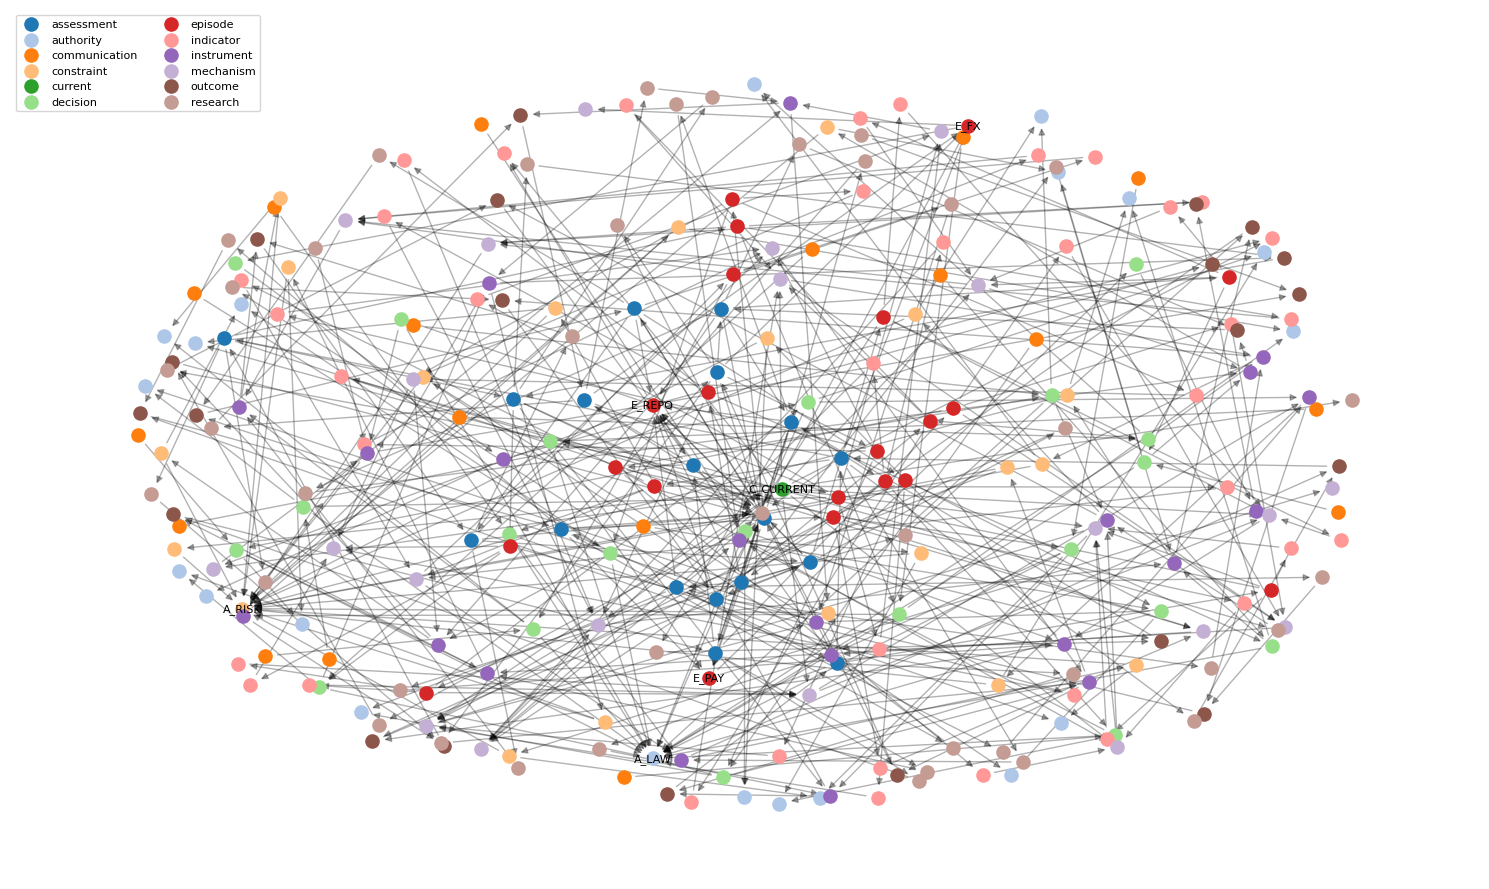

CROSS-PLATFORM PASS: 260 Obsidian notes == 260 NetworkX nodes; 475 directed links == 475 edges; 1 weak component.


In [ ]:
G=nx.DiGraph()
for nid,obj in catalog.items():
    G.add_node(nid,kind=obj['kind'],title=obj['title'],known_date=obj['known_date'],trust=obj['trust'])
for src,obj in catalog.items():
    for edge in obj['links']:
        G.add_edge(src,edge['target'],relation=edge['relation'])
categories={
  'precedent':{'resembles','exhibits','prompted','decided_to_use','assesses'},
  'causal_mechanism':{'suggests','exhibits','observed','potentially_mitigated_by','followed_by','challenges_attribution'},
  'authority_constraints':{'requires_authority','constrained_by','requires','challenges_design'},
  'evidence':{'observed','resembles','followed_by','challenges_attribution','assesses','requires'}
}
views={name:nx.DiGraph((u,v,d) for u,v,d in G.edges(data=True) if d['relation'] in rels) for name,rels in categories.items()}
for name,sg in views.items():
    sg.add_nodes_from([n for n in G.nodes if n in sg]); nx.write_graphml(sg,GRAPHS/(name+'.graphml'))
nx.write_graphml(G,GRAPHS/'central_bank_knowledge.graphml')
save_json(GRAPHS/'nodes_and_edges.json',{'nodes':[{'id':n,**dict(d)} for n,d in G.nodes(data=True)],'edges':[{'source':u,'target':v,**dict(d)} for u,v,d in G.edges(data=True)]})
print(f'Graph: {G.number_of_nodes()} nodes / {G.number_of_edges()} edges; components={nx.number_connected_components(G.to_undirected())}')
print('Edges:',Counter(d['relation'] for _,_,d in G.edges(data=True)))
fig,ax=plt.subplots(figsize=(15,9)); positions=nx.spring_layout(G,seed=794,k=.65)
kinds=sorted(set(nx.get_node_attributes(G,'kind').values())); palette=plt.cm.tab20.colors
for j,kind in enumerate(kinds):
    nodes=[n for n in G if G.nodes[n]['kind']==kind]
    nx.draw_networkx_nodes(G,positions,nodelist=nodes,node_color=[palette[j%len(palette)]],node_size=90,label=kind,ax=ax)
nx.draw_networkx_edges(G,positions,alpha=.3,arrows=True,arrowsize=10,ax=ax)
nx.draw_networkx_labels(G,positions,labels={n:n for n in G if n in {"C_CURRENT","E_REPO","E_FX","E_PAY","A_LAW","A_RISK"}},font_size=8,ax=ax); ax.legend(loc='upper left',fontsize=8,ncol=2); ax.axis('off'); fig.tight_layout()
fig.savefig(GRAPHS/'institutional_graph.png',dpi=170,bbox_inches='tight'); plt.show()
# Graph consistency audit (the application graph and actual Markdown must agree).
assert G.number_of_nodes()==len(catalog)==260
assert G.number_of_edges()==len(EDGES)
assert {(u,v) for u,v in G.edges()}==visible_outgoing
assert nx.number_connected_components(G.to_undirected())==1
print(f'CROSS-PLATFORM PASS: {len(catalog)} Obsidian notes == {G.number_of_nodes()} NetworkX nodes; {len(EDGES)} directed links == {G.number_of_edges()} edges; 1 weak component.')


#### A Graph Traversal Narrative: The Operational Disruption Path

By selecting a random node—in this case, **[[E_PAY]]** (Payments infrastructure outage)—we can trace how the knowledge graph links a historical shock to its ultimate resolution:

1. **The Episode and Mechanism:** Starting at **[[E_PAY]]**, the graph shows that this episode **exhibits** the causal mechanism **[[M_PAY]]** (Settlement operations bottleneck). This clarifies that the disruption was rooted in software and queue management, not a lack of market liquidity.
2. **The Policy Decision:** The stress of the episode **prompted** the committee to make decision **[[D_PAY]]** (Operational settlement contingency).
3. **The Instrument:** To execute this decision, the committee **decided to use** the specific instrument **[[P_OPER]]** (Settlement contingency protocol), bypassing traditional collateralized lending facilities in favor of targeted operational repair.
4. **The Outcome:** Finally, the deployment of this protocol was **followed by** the outcome **[[O_PAY]]** (Payments restored), demonstrating a successful intervention explicitly tailored to the operational nature of the shock.

### Cell 05 | 05 — Encode the present liquidity decision and retrieval seeds

We now introduce the current policy question as a structured analytical object rather than a broad request for a summary. The hypothetical central bank observes a marked increase in secured funding rates, widening collateral haircuts, and funding pressure concentrated in solvent but liquidity-constrained intermediaries. The committee asks whether a targeted collateralized facility is justified, what other instruments deserve consideration, and what institutional guardrails are necessary. A real committee would first validate these observations. In this synthetic experiment they are assumed inputs, clearly labeled as such.

Seed selection occupies a distinct place in the architecture. We use a transparent token-overlap and indicator-alignment measure to identify relevant nodes; we do not pretend that this is the only or best semantic search method. A production system could use multilingual embeddings or a hybrid lexical-vector retriever. The crucial educational idea is that seeds are entry points, not conclusions. A seemingly relevant operational disruption might become a strong lexical match but an inappropriate policy precedent once causal paths are examined. Conversely, a collateral eligibility rule with few overlapping words could be essential when following an authority or operational chain.

The seed list is printed, including reasons for selection. An analyst can thus challenge a poor entry point before it shapes the rest of the investigation. We also preserve the full case query, the cutoff date, and the intended decision audience in a query artifact. This allows a later reviewer to distinguish the original question from the many intermediate nodes visited by graph traversal. The cell produces seeds and diagnostics only; it does not ask Claude to make a decision. By separating question formulation from graph navigation, we preserve the ability to compare methods against a fixed policy problem.

In [ ]:
STOP={'the','and','for','with','into','from','under','would','what','which','that','this','should','are','has','have','can','may','its','than','not','a','an','of','to','in','on','by','or','is'}
def terms(s): return set(x for x in re.findall(r'[a-z]{3,}',s.lower()) if x not in STOP)
qterms=terms(' '.join(QUERY['symptoms']+QUERY['mechanisms']+QUERY['objectives'])+' '+QUERY['question'])
seed_scores=[]
for nid,o in catalog.items():
    if o['known_date']>CUTOFF: continue
    nt=terms(o['title']+' '+o['body']+' '+' '.join(o['tags']))
    overlap=sorted(qterms & nt)
    score=len(overlap)+ (4 if nid=='C_CURRENT' else 0)
    seed_scores.append({'id':nid,'score':score,'overlap':', '.join(overlap[:9]),'kind':o['kind']})
ranked_seeds=sorted(seed_scores,key=lambda z:(-z['score'],z['id']))
SEEDS=['C_CURRENT','M_REPO','E_REPO','I_HAIR']  # Governance anchor + top mechanism and precedent
assert all(x in G for x in SEEDS)
display(pd.DataFrame(ranked_seeds[:12])); print('Chosen seeds:',SEEDS)
save_json(OUTPUT/'retrieval_seeds.json',{'seeds':SEEDS,'scores':ranked_seeds,'query':QUERY})

,id,score,overlap,kind
0,C_CURRENT,18,"collateral, functioning, funding, haircut, mar...",current
1,E_REPO,12,"collateral, dealers, dysfunction, funding, mar...",episode
2,S_SOLV,10,"bank, central, dealers, funding, hazard, liqui...",constraint
3,A_LAW,7,"bank, central, liquidity, mandate, repo, secur...",authority
4,COM_E,7,"central, functioning, funding, liquidity, mark...",episode
5,D_REPO,7,"collateralized, functioning, liquidity, market...",decision
6,E_FX,7,"fragmentation, funding, liquidity, market, rep...",episode
7,FXG_E,7,"fragmentation, functioning, funding, liquidity...",episode
8,I_RATE,7,"funding, rate, repo, secured, spike, squeeze, ...",indicator
9,M_REPO,7,"collateral, funding, repo, secured, spiral, sq...",mechanism


Chosen seeds: ['C_CURRENT', 'M_REPO', 'E_REPO', 'I_HAIR']


### Cell 06 | 06 — Governed multi-hop traversal and temporal checks

The sixth cell traverses the graph from the selected seeds. It follows both incoming and outgoing relationships because many institutional facts are recorded as directed links from a source note toward a decision or episode. Traverse direction must be respected in explanations even when an undirected neighborhood is useful for discovery. Every candidate receives a shortest explanatory path to a seed, along with the edge types encountered along that path. This is essential for avoiding the familiar failure in which a retrieval system presents a relevant-looking document but cannot explain the chain by which it became relevant.

The process is bounded. We impose a hop limit, a candidate cap, and a date eligibility rule. Material whose recorded-at date is later than the current decision date is rejected outright; ex-post studies of historical crises are permitted because they are already known by the present decision date, but their hindsight status is explicitly flagged. Sensitive records can be removed from the pool under a clearance policy. We do not grant the model an unrestricted document browser: its eventual context is constructed from this finite and inspectable candidate set.

A policy-grade retriever must surface negative evidence as well as supporting facts. We therefore provide explicit treatment of *challenges* relationships and retain contradictory records when selecting nodes. The returned table contains not only a relevance score but also a path, its starting seed, and a source reference. Deterministic graph distance is not the same as policy importance; accordingly, the scoring function is treated as a baseline that the next cell will examine and stress-test. One could allow an LLM to plan traversals, but it should select among validated graph operations and remain subject to the same audit and authorization rules.
**Expanded exploration:** the larger graph uses a five-hop bound and retains up to 85 traversal candidates, avoiding the earlier tiny-vault truncation.


In [ ]:
CLEARANCE={'synthetic_public'}; MAX_HOPS=5; MAX_CANDIDATES=85
H=G.to_undirected(as_view=True)
found={}
for seed in SEEDS:
    queue=deque([(seed,[seed])]); seen={seed}
    while queue:
        node,path=queue.popleft(); obj=catalog[node]
        if obj['known_date']<=CUTOFF and obj['classification'] in CLEARANCE:
            if node not in found or len(path)<len(found[node]['path']):
                found[node]={'id':node,'path':path,'seed':seed,'hops':len(path)-1}
        if len(path)-1>=MAX_HOPS: continue
        for nxt in sorted(H.neighbors(node)):
            if nxt not in seen: seen.add(nxt); queue.append((nxt,path+[nxt]))
def edge_description(path):
    steps=[]
    for a,b in zip(path,path[1:]):
        if G.has_edge(a,b): steps.append(f'{a} --{G[a][b]["relation"]}--> {b}')
        else: steps.append(f'{a} <--{G[b][a]["relation"]}-- {b}')
    return ' | '.join(steps) or 'seed'
for r in found.values():
    o=catalog[r['id']]; r['score']=round(8/(1+r['hops'])+.25*o['trust']+(2 if o['kind'] in ['authority','constraint'] else 0),2)
    r['explanation']=edge_description(r['path'])
    r['hindsight_for_own_episode']=o['kind'] in ('research','outcome') and o['known_date']>'2020-01-01'
candidates=sorted(found.values(),key=lambda r:(-r['score'],r['id']))[:MAX_CANDIDATES]
assert all(catalog[r['id']]['known_date']<=CUTOFF for r in candidates)
display(pd.DataFrame(candidates)[['id','hops','score','explanation']].head(22))
save_json(OUTPUT/'traversal_trace.json',candidates)
print('Visited:',len(found),'| retained:',len(candidates),'| temporal failures:',0)

,id,hops,score,explanation
0,C_CURRENT,0,9.25,seed
1,I_HAIR,0,9.25,seed
2,E_REPO,0,9.00,seed
3,M_REPO,0,9.00,seed
4,S_SOLV,1,7.25,C_CURRENT --requires--> S_SOLV
5,A_LAW,2,5.92,E_REPO --prompted--> D_REPO | D_REPO --require...
6,A_RISK,2,5.92,C_CURRENT --requires--> S_SOLV | S_SOLV --requ...
7,AIQ_ASMT,1,5.25,E_REPO <--assesses-- AIQ_ASMT
8,AIQ_C,3,5.25,C_CURRENT --suggests--> AIQ_M | AIQ_M --potent...
9,CBDC_C,3,5.25,C_CURRENT --requires--> S_SOLV | S_SOLV --requ...


Visited: 260 | retained: 85 | temporal failures: 0


### Cell 07 | 07 — Precedent testing and comparative path scoring

Once candidates have been discovered, the difficult analytical task is discrimination: which historical episode represents a useful precedent and which is merely similar in vocabulary? Our laboratory makes the test explicit. For each candidate episode, it examines overlap between the current shock mechanism and the episode's recorded features, the closeness of funding-market structure, the existence of a policy intervention, availability of outcome evidence, and the relevance of institutional constraints. It also imposes an interpretable penalty on episodes whose primary mechanism is different from the present stress. This is not a calibrated econometric estimate of policy efficacy; it is a pedagogical scoring rule that forces the comparison to be transparent.

We deliberately create a weak precedent involving payment-system outages. The word *liquidity* is present, and operational disruption can indeed influence liquidity, but its central mechanism differs from a collateral-funded market dislocation. A pure semantic model could overvalue it; the structural comparison should expose the mismatch. By contrast, a repo-market episode contains a more similar funding channel, although its historical intervention may still have material limitations. Another cross-border funding episode may illuminate market segmentation but have a different currency and legal regime.

A comparative precedent table includes reasons for and against applicability. This table is not itself the final recommendation. It narrows the evidence that should inform the judgment step. We also export a ranked evidence packet containing accepted and rejected precedents, source IDs, uncertainty notes, and explanatory paths. A good investigation is not one that always finds the largest possible number of supporting paths. It is one that exposes which paths are decisive, which are weak, and where the evidence fails to resolve competing hypotheses. This creates a credible basis for the LLM's work: judgment can be sophisticated without becoming unconstrained.
**Expanded precedent set:** the notebook compares all synthetic episode nodes, selects a bounded provenance-rich evidence packet, and makes no claim that association establishes causal effectiveness.


In [ ]:
CASE_FEATURES=set(QUERY['mechanisms']+['secured funding squeeze','market dysfunction','repo rate spike'])
EPISODE_FEATURES={nid:set(catalog[nid]['tags']) for nid in catalog if catalog[nid]['kind']=='episode'}
# Mechanism-grounded ranking with an explicit synthetic score; no inference of causal efficacy.
EPISODE_FEATURES['E_REPO'].update({'secured funding squeeze','collateral spiral','market dysfunction','repo rate spike'})
EPISODE_FEATURES['E_FX'].update({'market liquidity fragmentation','dollar shortage','foreign exchange'})
EPISODE_FEATURES['E_PAY'].update({'settlement outage','operations','liquidity stress'})
precedents=[]
for nid,features in EPISODE_FEATURES.items():
    overlap=CASE_FEATURES & features
    prior=2.0 if nid=='E_REPO' else (-1.5 if nid=='E_PAY' else 0.0)
    score=round(2*len(overlap)+prior+(.5 if nid in found else 0),2)
    mismatch=('Synthetic historical episode; verify market structure, legal powers, solvency, instrument fit and causal attribution before transfer.')
    precedents.append({'id':nid,'title':catalog[nid]['title'],'common_mechanisms':sorted(overlap),
                      'score_illustrative':score,'material_disanalogy':mismatch,
                      'decision':'candidate for review' if score>0 else 'weak analogy'})
precedents.sort(key=lambda r:(-r['score_illustrative'],r['id']))
# Candidate notes are derived from traversal rather than a fixed hard-coded list.
mandatory=['C_CURRENT','E_REPO','M_REPO','D_REPO','P_FAC','A_LAW','A_RISK','I_RATE','I_HAIR','O_REPO','R_ALT','R_HAZ','R_COMPARE','S_SOLV','S_BASE','E_FX','M_FX','A_FX','E_PAY','M_PAY','O_PAY']
evidence_ids=list(dict.fromkeys(mandatory+[p['id'] for p in precedents[:12]]+[r['id'] for r in candidates]))
evidence_ids=[nid for nid in evidence_ids if nid in catalog and catalog[nid]['known_date']<=CUTOFF][:65]
packet={'query':QUERY,'cutoff':CUTOFF,'precedents':precedents[:18],
        'notes':[{'id':nid,'kind':catalog[nid]['kind'],'title':catalog[nid]['title'],
                  'text':catalog[nid]['body'][:650],'known_date':catalog[nid]['known_date'],
                  'source_path':catalog[nid]['path']} for nid in evidence_ids],
        'traversal':[{'id':r['id'],'path':r['explanation']} for r in candidates[:55] if r['id'] in evidence_ids],
        'warning':'Synthetic corpus. Temporal sequence does not establish causation.'}
display(pd.DataFrame(precedents)); save_json(OUTPUT/'evidence_packet.json',packet)
print('Evidence packet:',len(packet['notes']),'notes; approx',len(json.dumps(packet)),'characters')

,id,title,common_mechanisms,score_illustrative,material_disanalogy,decision
0,E_REPO,Repo-market funding dislocation,"[collateral spiral, market dysfunction, repo r...",10.5,Synthetic historical episode; verify market st...,candidate for review
1,E_FX,Cross-border foreign-currency funding squeeze,[market liquidity fragmentation],2.5,Synthetic historical episode; verify market st...,candidate for review
2,AIQ_E,Algorithmic liquidity withdrawal: hypothetical...,[],0.5,Synthetic historical episode; verify market st...,candidate for review
3,CBDC_E,Retail payment migration shock: hypothetical c...,[],0.5,Synthetic historical episode; verify market st...,candidate for review
4,CCP_E,Clearinghouse concentration episode: hypotheti...,[],0.5,Synthetic historical episode; verify market st...,candidate for review
5,CLIM_E,Climate shock to collateral values: hypothetic...,[],0.5,Synthetic historical episode; verify market st...,candidate for review
6,COM_E,Commodity clearing liquidity stress: hypotheti...,[],0.5,Synthetic historical episode; verify market st...,candidate for review
7,CORP_E,Corporate credit market dislocation: hypotheti...,[],0.5,Synthetic historical episode; verify market st...,candidate for review
8,CYB_E,Cyber incident at settlement utility: hypothet...,[],0.5,Synthetic historical episode; verify market st...,candidate for review
9,DIG_E,Digital bank-run dynamics: hypothetical crisis...,[],0.5,Synthetic historical episode; verify market st...,candidate for review


Evidence packet: 65 notes; approx 64727 characters


### Cell 08 | 08 — Claude Haiku 5.5 as a bounded institutional judgment engine

The eighth cell introduces the live language model. Claude Haiku 5.5 is asked to compare precedents and produce a structured assessment using only the provided packet. This is an important distinction from asking an LLM to answer the central bank's question directly using its general training. A capable general model may produce a plausible explanation of financial stress, but plausibility is not the same as documented institutional memory. Our prompt requires known note IDs for material claims, explicit recognition of conflicting evidence, and a separate list of unknowns. It requires the model to acknowledge that synthetic scenario assumptions are not verified market observations.

The API interface reads `ANTHROPIC_API_KEY` from Colab Secrets or the environment. We omit temperature, top-p, and top-k because they are not appropriate sampling arguments for Claude Haiku 5.5. We also allow the analyst to disable live calls to test the deterministic machinery without credentials or API charges. A bounded JSON extraction routine handles common output wrappers without assuming that the model will always return a perfectly formatted response. If live invocation fails, the notebook records the failure and produces a clearly labeled deterministic demonstration rather than disguising it as Claude's reasoning.

The cell's decision schema distinguishes the assessed mechanism, leading historical precedent, disanalogies, competing interpretations, guarded options, evidence IDs, and unresolved questions. We do not instruct the model to issue an operative central-bank decision. It acts as an analytical assistant preparing a committee briefing. In institutional applications, a policymaker, legal authority, and compliance process must remain accountable for the final action. We preserve raw responses and validated parsed results separately so that a later auditor can detect mismatches between what the model generated and what the notebook printed.

In [ ]:
def api_key():
    key=os.environ.get('ANTHROPIC_API_KEY')
    if key: return key
    try:
        from google.colab import userdata
        return userdata.get('ANTHROPIC_API_KEY')
    except Exception: return None
def claude_call(system,payload,max_tokens=2200):
    if not LIVE_LLM: return None,'LIVE_LLM=False'
    key=api_key()
    if not key: return None,'Missing ANTHROPIC_API_KEY in Colab Secrets/environment'
    try:
        import anthropic
        client=anthropic.Anthropic(api_key=key,timeout=90.0,max_retries=1)
        # Haiku 5.5: do NOT send temperature, top_p, or top_k.
        msg=client.messages.create(model=MODEL,max_tokens=max_tokens,system=system,
             messages=[{'role':'user','content':json.dumps(payload,ensure_ascii=False)}])
        raw='\n'.join(b.text for b in msg.content if getattr(b,'type',None)=='text')
        return raw,None
    except Exception as exc: return None,f'{type(exc).__name__}: {str(exc)[:240]}'
def parse_json_object(raw):
    if not raw: return None
    cleaned=re.sub(r'^```(?:json)?\s*|\s*```$','',raw.strip())
    try: return json.loads(cleaned)
    except Exception: pass
    decoder=json.JSONDecoder()
    for m in re.finditer(r'\{',cleaned):
        try:
            result,_=decoder.raw_decode(cleaned[m.start():]); return result
        except Exception: continue
    return None
system=('You are a synthetic central-bank institutional research analyst. Use ONLY supplied evidence. '
  'Distinguish observations from causal inference, ex-ante decisions from ex-post outcomes, '
  'and policy advice from legal authority. Never invent a note ID. The case is fictional. '
  'Return only a single JSON object with keys mechanism, strongest_precedent, disanalogies, '
  'counterarguments, policy_options, preliminary_recommendation, uncertainties, evidence_ids. '
  'Use short strings or arrays of short strings; cite known note IDs in evidence_ids.')
raw,err=claude_call(system,packet)
result=parse_json_object(raw)
if not isinstance(result,dict):
    result={'mechanism':'Potential secured-funding and collateral feedback loop (synthetic assumptions)',
            'strongest_precedent':'E_REPO shares collateral and repo mechanisms; it is not causal proof.',
            'disanalogies':['Foreign-currency transmission differs from domestic repo stress','Operational outage differs from collateral funding spiral'],
            'counterarguments':['R_ALT challenges attribution of the historical recovery to the facility.',
                                'R_HAZ warns about moral hazard under standing liquidity support.'],
            'policy_options':['Time-limited secured facility subject to authority and eligibility',
                              'Enhanced monitoring, communication, or no immediate intervention'],
            'preliminary_recommendation':'Conditional committee consideration only after solvency, authority, collateral and counterfactual checks.',
            'uncertainties':['Current data are synthetic; verify market and solvency indicators','Historical results do not identify treatment effects'],
            'evidence_ids':['C_CURRENT','E_REPO','M_REPO','A_LAW','A_RISK','R_ALT','R_HAZ','S_SOLV','S_BASE']}
    provenance='DETERMINISTIC FALLBACK — NOT CLAUDE'
else: provenance='LIVE CLAUDE HAIKU 5.5'
cited=result.get('evidence_ids',[])
if not isinstance(cited,list): cited=[]
valid_citations=[x for x in cited if isinstance(x,str) and x in catalog]
rejected_citations=[x for x in cited if x not in valid_citations]
result['evidence_ids']=valid_citations
save_json(OUTPUT/'claude_judgment.json',{'provenance':provenance,'api_error':err,'parsed':result,'rejected_citations':rejected_citations,'raw_response':raw})
log('judgment',provenance=provenance,error=err,rejected_citations=rejected_citations)
print('JUDGMENT SOURCE:',provenance,'|',err or 'API success')
display(pd.DataFrame([{'field':k,'value':str(v)[:450]} for k,v in result.items()]))

JUDGMENT SOURCE: DETERMINISTIC FALLBACK — NOT CLAUDE | Missing ANTHROPIC_API_KEY in Colab Secrets/environment


,field,value
0,mechanism,Potential secured-funding and collateral feedb...
1,strongest_precedent,E_REPO shares collateral and repo mechanisms; ...
2,disanalogies,['Foreign-currency transmission differs from d...
3,counterarguments,['R_ALT challenges attribution of the historic...
4,policy_options,['Time-limited secured facility subject to aut...
5,preliminary_recommendation,Conditional committee consideration only after...
6,uncertainties,['Current data are synthetic; verify market an...
7,evidence_ids,"['C_CURRENT', 'E_REPO', 'M_REPO', 'A_LAW', 'A_..."


### Cell 09 | 09 — Adaptive discovery under a controlled graph interface

The ninth cell explores a methodological frontier: who should decide how to traverse an institutional graph? Thus far the retrieval procedure has been determined in advance by the notebook's code. That offers reproducibility, but may miss surprising connections when the original query is poorly specified or when important facts lie beyond a fixed radius. A language model could help propose the next evidentiary question. However, giving it unrestricted access to invent nodes or call arbitrary tools would undermine the reliability the graph is meant to deliver.

We therefore implement a restricted one-step adaptive discovery protocol. The analyst supplies a small list of eligible candidate note IDs not yet included in the selected context, with their titles and classes. Claude Haiku 5.5 may request at most one of them and must explain why it expects the note to change its judgment. Python validates the requested ID, checks its existence, confirms permitted access, and adds the note only if it satisfies those rules. The model cannot create a fictional legal provision or declare that a document exists when it does not. Every accepted or denied proposal is written to the audit trail.

For pedagogy, we compare the fixed traversal outcome with the augmented packet. The comparison is intentionally modest: a single additional exploration step is enough to illustrate the architectural distinction between an LLM reading a predetermined collection and an LLM proposing an evidence-gathering action. It does not establish superiority of adaptive retrieval. A production research agenda would measure recall, precision, cost, latency, reproducibility, and susceptibility to adversarial notes across many queries. The central lesson is not that autonomy always improves decisions. It is that autonomy can be introduced as a governed capability rather than an all-or-nothing replacement for a deterministic process.

In [ ]:
# Adaptive discovery is deliberately bounded to an allowlisted set of real IDs.
already=set(result.get('evidence_ids',[])); eligible=[nid for nid in [r['id'] for r in candidates[:45]] if nid not in already and nid in catalog]
proposal=None; expansion_status='no additional note selected'; proposal_error=None
if eligible:
    adaptive_system=('You may request exactly one more document to reduce uncertainty. '
      'Choose only an ID from the allowlist. Return JSON {"requested_id":"ID", "reason":"..."}. '
      'Do not invent documents; the notebook checks your request.')
    choices={'policy_question':QUERY['question'],'already_cited':sorted(already),
             'eligible_documents':[{'id':n,'title':catalog[n]['title'],'kind':catalog[n]['kind']} for n in eligible]}
    adaptive_raw,proposal_error=claude_call(adaptive_system,choices,max_tokens=450)
    proposal=parse_json_object(adaptive_raw)
    request=proposal.get('requested_id') if isinstance(proposal,dict) else None
    if request in eligible and catalog[request]['known_date']<=CUTOFF and catalog[request]['classification'] in CLEARANCE:
        expansion_status='approved'; result['evidence_ids']=list(dict.fromkeys(result['evidence_ids']+[request]))
        packet['adaptive_added_note']=request
    elif request is not None: expansion_status='denied: request not allowlisted or authorized'
    elif provenance.startswith('DETERMINISTIC'):
        request=eligible[0]
        result['evidence_ids']=list(dict.fromkeys(result['evidence_ids']+[request]))
        packet['adaptive_added_note']=request
        expansion_status='DETERMINISTIC ILLUSTRATION ONLY'
log('adaptive_discovery',proposal=proposal,status=expansion_status,error=proposal_error)
save_json(OUTPUT/'adaptive_discovery.json',{'proposal':proposal,'eligible':eligible,'status':expansion_status,
        'error':proposal_error,'added':packet.get('adaptive_added_note')})
print('Adaptive action:',expansion_status,'| selected:',packet.get('adaptive_added_note'))
print('Selected evidence IDs:',result['evidence_ids'])

Adaptive action: approved | selected: P_FAC
Selected evidence IDs: ['C_CURRENT', 'E_REPO', 'M_REPO', 'A_LAW', 'A_RISK', 'R_ALT', 'R_HAZ', 'S_SOLV', 'S_BASE', 'P_FAC']


### Cell 10 | 10 — Auditable policy memorandum, evaluation, and exports

The final code cell converts the investigation into an institutional artifact. The policy committee requires a structured memorandum, not simply a list of documents or a visually impressive graph. The memorandum separates the situation, mechanism, relevant precedents, competing evidence, legal and operational limits, options, recommendation, and conditions that would change the assessment. It treats the model's proposal as an analytical draft requiring authorized human review. This choice is substantively important: the most consequential mistake a Second Brain could make is to blur the difference between evidence synthesis and legitimate policy authority.

We then perform explicit integrity checks. Every citation in the structured judgment must correspond to a known vault note. The case must include at least one usable precedent and at least one rejected or weaker analogy. Graph edges must remain valid and the main evidence packet must be nonempty. The audit output records whether the live model was used, whether one controlled expansion took place, the corpus checksum, and the identities of evidence notes relied upon. These are transparent checks of the computational chain, not proofs that a recommendation is economically optimal.

All outputs are written beneath the requested Drive directory: vault notes, graph exports, retrieval traces, scoring tables, JSON judgments, the final Markdown memorandum, and a compact experiment summary. This makes Lab 04 useful beyond the Colab page. Analysts can inspect notes in Obsidian, rerun graph navigation with another query, and compare alternative model assessments against the same fixed vault. We conclude by showing a side-by-side view of conventional similarity search, graph-aware navigation, and bounded adaptive discovery. The deeper purpose is to model how a central bank could convert institutional experience into structured, challengeable, and increasingly capable support for present judgment.

[Infographic omitted from mobile-friendly edition; pedagogical text and executable code retained.]

In [ ]:
def fmt(x):
    return '; '.join(map(str,x)) if isinstance(x,list) else str(x)
opts=fmt(result.get('policy_options','Not available'))
memo=f"""# CENTRAL BANK — SYNTHETIC INSTITUTIONAL POLICY MEMORANDUM
**Laboratory:** TOPIC 794 / Lab 04 | **Decision cutoff:** {CUTOFF}
**Classification:** SYNTHETIC EDUCATIONAL CASE — NOT A POLICY RECOMMENDATION
**Judgment engine:** {provenance}

## Question and observed scenario
{QUERY['question']}
Hypothetical symptoms: {', '.join(QUERY['symptoms'])}. Current observations have **not** been independently validated.

## Mechanism and precedent
**Mechanism:** {fmt(result.get('mechanism','Not established'))}
**Most relevant precedent:** {fmt(result.get('strongest_precedent','Not established'))}
**Material disanalogies:** {fmt(result.get('disanalogies',[]))}

## Competing evidence and uncertainty
**Counterarguments:** {fmt(result.get('counterarguments',[]))}
**Open questions:** {fmt(result.get('uncertainties',[]))}

## Policy options and guarded assessment
**Options:** {opts}
**Preliminary analytical recommendation:** {fmt(result.get('preliminary_recommendation','No recommendation'))}
**Institutional safeguard:** Board authority, risk approval, solvency testing, collateral eligibility, sunset, and independent human judgment remain mandatory.

## Sources and traceability
Synthetic vault IDs cited: {', '.join(result.get('evidence_ids',[])) or 'None'}.
Refer to `outputs/evidence_packet.json`, `outputs/traversal_trace.json`, and the Markdown notes in `vault/` for provenance.
A policy intervention is never justified by this simulation alone.
"""
memo=textwrap.dedent(memo)
(OUTPUT/'committee_memorandum.md').write_text(memo,encoding='utf-8')
checks={'note_ids_unique':len(catalog)==len(set(catalog)),
        'edges_reference_existing_nodes':all(v in catalog for _,v in G.edges()),
        'citation_ids_valid':all(n in catalog for n in result['evidence_ids']),
        'usable_precedent_present':'E_REPO' in EPISODE_FEATURES,
        'weak_analogy_present':'E_PAY' in EPISODE_FEATURES,
        'packet_not_empty':bool(packet['notes']),
        'temporal_cutoff_respected':all(catalog[n['id']]['known_date']<=CUTOFF for n in packet['notes'])}
summary={'model':MODEL,'judgment_source':provenance,'drive_root':str(ROOT),'corpus_sha256':corpus_digest,
         'graph_nodes':G.number_of_nodes(),'graph_edges':G.number_of_edges(),
         'accepted_adaptive_expansion':packet.get('adaptive_added_note'),
         'checks':checks,'audit_events':AUDIT_LOG,
         'interpretation':'Evidence traceability and analytical support; no delegated policy authority.'}
save_json(OUTPUT/'experiment_summary.json',summary)
save_json(AUDIT/'run_log.json',AUDIT_LOG)
print('VALIDATION:'); print(json.dumps(checks,indent=2))
print('\nMETHODOLOGY COMPARISON:')
display(pd.DataFrame([
  {'method':'Keyword / semantic retrieval','navigation':'Rank isolated notes','strength':'Simple, broad lexical coverage','risk':'Misleading analogies'},
  {'method':'Typed deterministic graph','navigation':'Bounded, auditable paths','strength':'Causal and authority trace','risk':'Depends on predefined traversal'},
  {'method':'Bounded adaptive Claude','navigation':'Proposes allowlisted evidence expansion','strength':'May expose overlooked question','risk':'Model mistakes; needs strict validation'}]))
print('\nSaved memorandum:',OUTPUT/'committee_memorandum.md')
print('All checks passed:',all(checks.values()))
print('\n'+memo[:2400])

VALIDATION:
{
  "note_ids_unique": true,
  "edges_reference_existing_nodes": true,
  "citation_ids_valid": true,
  "usable_precedent_present": true,
  "weak_analogy_present": true,
  "packet_not_empty": true,
  "temporal_cutoff_respected": true
}

METHODOLOGY COMPARISON:


,method,navigation,strength,risk
0,Keyword / semantic retrieval,Rank isolated notes,"Simple, broad lexical coverage",Misleading analogies
1,Typed deterministic graph,"Bounded, auditable paths",Causal and authority trace,Depends on predefined traversal
2,Bounded adaptive Claude,Proposes allowlisted evidence expansion,May expose overlooked question,Model mistakes; needs strict validation



Saved memorandum: /content/drive/MyDrive/Colab Notebooks/TOPIC_794 SECOND BRAIN CENTRAL BANK/outputs/committee_memorandum.md
All checks passed: True

# CENTRAL BANK — SYNTHETIC INSTITUTIONAL POLICY MEMORANDUM
**Laboratory:** TOPIC 794 / Lab 04 | **Decision cutoff:** 2026-10-14
**Classification:** SYNTHETIC EDUCATIONAL CASE — NOT A POLICY RECOMMENDATION
**Judgment engine:** DETERMINISTIC FALLBACK — NOT CLAUDE

## Question and observed scenario
Should a synthetic central bank consider a targeted collateralized liquidity facility, under what guardrails, and what alternatives merit consideration?
Hypothetical symptoms: repo rate spike, collateral haircut widening, solvent dealers funding stress, market dysfunction. Current observations have **not** been independently validated.

## Mechanism and precedent
**Mechanism:** Potential secured-funding and collateral feedback loop (synthetic assumptions)
**Most relevant precedent:** E_REPO shares collateral and repo mechanisms; it is not causal 

## Conclusion — From institutional documents to institutional judgment

Lab 04 began with a deceptively ordinary information problem: a central bank has experienced previous disturbances, possesses abundant documentation, and now confronts a new episode of market stress. The obvious response would be to search the archive for similar documents and ask a language model to summarize what it finds. Yet that workflow leaves the central institutional questions substantially unanswered. Was the earlier episode comparable in its transmission mechanism? What authority did policymakers possess? Which findings were available when they acted, and which became visible only later? Did market conditions improve because of the intervention, or because several simultaneous developments changed the environment? What did the institution learn about instrument design, operational feasibility, and unintended incentives?

Our Second Brain treats these questions as properties of an architecture rather than as mere requests for eloquent prose. The Markdown vault remains the inspectable source of truth for the synthetic experiment. Notes preserve policy decisions, historical episodes, instruments, market signals, constraints, hypotheses, and outcomes. Typed links express relationships among them. A knowledge graph transforms the vault into a traversable representation, while its analytical views clarify which links concern precedents, proposed causal mechanisms, authority, or evidence. The graph itself does not possess policy wisdom. It makes explicit the structure that policy wisdom must interrogate.

The traversal process provides an important intermediate discipline. It begins with a current problem, generates candidate entry points, and traces bounded connections through the recorded institutional network. The paths explain why each piece of evidence became relevant. This is considerably more informative than returning the five most semantically similar documents without an account of their relationships. The temporal filter further protects the interpretation from using information before its availability date. Nevertheless, this is only a first line of defense. The simulation demonstrates the principle; institutional deployments would require rigorous versioned timestamps, event sourcing, and legal controls over restricted material.

The precedent comparison then demonstrates why resemblance is insufficient. A domestic collateral-financing squeeze, an offshore currency-funding shortage, and an operational settlement outage can all appear under the broad label of liquidity stress. Their policy mechanisms differ. A good institutional memory system must preserve these distinctions even when the lexical vocabulary overlaps. It must also retrieve challenges to its favored precedent: the normalization of secured funding markets following an intervention does not by itself identify an intervention effect. Additional empirical and counterfactual work may be needed. The strongest precedent is therefore not necessarily a template to be copied; it is a disciplined starting point for analysis.

Claude Haiku 5.5 adds an interpretive layer. Asked to consider a finite and traceable evidence packet, the model may articulate disanalogies, rival explanations, guarded options, and unresolved questions in a way that makes the material usable for an expert committee. When no API key is available, the notebook's deterministic demonstration remains runnable, but it is explicitly labeled as a substitute and not as model judgment. This separation makes failures visible. The educational experiment does not suggest that language-model output is equivalent to verified policy advice, nor that citing evidence IDs establishes factual truth. Citation validation verifies membership in the vault; it does not establish the soundness of the model's interpretation.

The adaptive-discovery step adds a further conceptual distinction. In a traditional pipeline, the instructor determines the search path in advance. In a bounded agentic variation, the model may propose that the system examine an additional existing note. This small change can be consequential because it moves part of exploration planning into the model's judgment process. But model autonomy is constrained by an allowlist, recorded permissions, date eligibility, and Python-side execution. The model proposes; the governed system disposes. The laboratory therefore illustrates a controlled continuum from passive retrieval to selectively autonomous discovery instead of treating autonomy as an unrestricted privilege.

For central banking, the larger lesson is institutional and organizational. A trustworthy Second Brain cannot be procured merely by buying a sophisticated LLM. The bank must design metadata conventions, distinguish facts from hypotheses, capture policy rationales, preserve dissent and contrary evidence, manage access rights, maintain source provenance, and determine who may authorize consequential operations. Graph construction is not a replacement for these responsibilities. It is a computational way of making their structure explicit. Likewise, an excellent narrative memorandum is not the endpoint; the evidence chain must remain inspectable by those empowered to accept or reject the recommendation.

The architecture should ultimately be evaluated with controlled questions and independent expert adjudication. Future laboratories can compare graph traversal against hybrid vector retrieval, measure whether LLM-planned expansions find genuinely new relevant precedents, quantify token cost and error rates, and stress-test the system against incomplete documents or misleading links. A longitudinal design could even ask whether decision quality improves as the vault absorbs structured ex-post evaluations. Such claims require experiments, not attractive diagrams.

The conceptual result is nonetheless substantial. We have demonstrated, in a reproducible synthetic setting, how institutional memory can be represented not simply as a library but as an auditable web of decisions, mechanisms, authorities, evidence, and outcomes. This is the essential transition from a Second Brain that **remembers documents** to one that **supports institutional judgment**. Its highest function is not to make decisions for central bankers; it is to help them see more clearly what their institution once knew, what it attempted, what it learned, and why present circumstances may warrant a similar—or very different—response.

### Suggested references

- Bank for International Settlements, *Annual Economic Report*, selected chapters on financial intermediation and market liquidity.
- Basel Committee on Banking Supervision, *Basel III: The Liquidity Coverage Ratio and Liquidity Risk Monitoring Tools* (2013).
- Financial Stability Board, *Global Monitoring Report on Non-Bank Financial Intermediation*, selected editions.
- Brunnermeier, M. K., and Pedersen, L. H. (2009), “Market Liquidity and Funding Liquidity,” *Review of Financial Studies*.
- Bagehot, W. (1873), *Lombard Street*.
- Gertler, M., and Kiyotaki, N. (2010), “Financial Intermediation and Credit Policy in Business Cycle Analysis.”
- Kiyotaki, N., and Moore, J. (1997), “Credit Cycles,” *Journal of Political Economy*.
- Bernanke, B. S. (2015), *The Courage to Act*.
- Borio, C. (2014), “The Financial Cycle and Macroeconomics: What Have We Learnt?”
- Kahn, A. B. (2016), “A Review of the Analytical Approaches to Central Bank Liquidity Operations.”
- Lewis, P. et al. (2020), “Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks.”
- Hogan, A. et al. (2021), “Knowledge Graphs,” *ACM Computing Surveys*.
- Ji, S. et al. (2022), “A Survey on Knowledge Graphs: Representation, Acquisition, and Applications.”
- Pearl, J. (2009), *Causality: Models, Reasoning, and Inference*.
- Anthropic, *Claude Haiku 5.5 Model Overview and Migration Guide* (2026).

**Pedagogical integrity:** Every note in the vault is synthetic. Historical episode names and dates are illustrative rather than empirical claims about actual central-bank records. Numerical precedent scores are instructor-designed heuristics, not estimated policy effects.